# Semana 1: Revisión de POO I — Diagnóstico, Refactorización y Calidad de Código

In [5]:
# SU SOLUCIÓN REFACTORIZADA — Práctica S1, Actividad 2
from dataclasses import dataclass


@dataclass
class Nota:
    curso: str
    calificacion: float


class Estudiante:
    def __init__(self, nombre: str, codigo: int, escuela: str):
        self._nombre = nombre
        self._codigo = codigo
        self._escuela = escuela
        self._historial_notas: list[Nota] = []

    @property
    def nombre(self) -> str:
        return self._nombre

    def agregar_nota(self, curso: str, calificacion: float) -> None:
        if not (0 <= calificacion <= 20):
            raise ValueError(f"La calificación debe estar en el rango [0, 20]. Valor recibido: {calificacion}")

        self._historial_notas.append(Nota(curso, calificacion))

    def calcular_ppa(self) -> float:
        if not self._historial_notas:
            return 0.0

        suma_calificaciones = sum(nota.calificacion for nota in self._historial_notas)
        return suma_calificaciones / len(self._historial_notas)

    def __str__(self) -> str:
        lineas = [
            f"Estudiante: {self._nombre} | Código: {self._codigo} | Escuela: {self._escuela}",
            "Notas:"
        ]
        for nota in self._historial_notas:
            lineas.append(f"  - {nota.curso}: {nota.calificacion}")
        return "\n".join(lineas)


# Prueba — debe ejecutar sin errores:
if __name__ == "__main__":
    e = Estudiante("Juan Carlos Mamani Quispe", 20210500, "Ing. Sistemas")
    e.agregar_nota("POO II", 16)
    e.agregar_nota("Base de Datos I", 14)
    print(e)
    print(f"PPA: {e.calcular_ppa():.2f}")

    try:
        e.agregar_nota("Redes", 25) # debe lanzar ValueError
    except ValueError as ex:
        print(f"Error capturado correctamente: {ex}")

Estudiante: Juan Carlos Mamani Quispe | Código: 20210500 | Escuela: Ing. Sistemas
Notas:
  - POO II: 16
  - Base de Datos I: 14
PPA: 15.00
Error capturado correctamente: La calificación debe estar en el rango [0, 20]. Valor recibido: 25


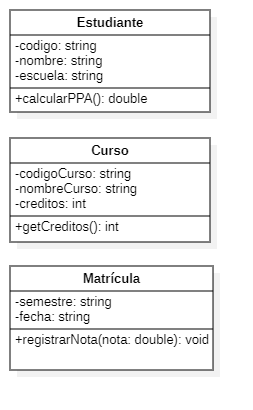

# Semana 2: Abstracción y Encapsulamiento: Invariantes, propiedades y Diseño por Responsabilidades

In [6]:
import re
from datetime import date

# --- Clase Curso ---
class Curso:
    _PATRON_CODIGO = re.compile(r"^SIS\d{3}$")

    def __init__(self, codigo: str, nombre: str, creditos: int, cupos_maximo: int):
        self.codigo = codigo
        self.nombre = nombre
        self.creditos = creditos
        self.cupos_maximo = cupos_maximo
        self.__inscritos = 0

    @property
    def codigo(self): return self.__codigo
    @codigo.setter
    def codigo(self, valor):
        if not self._PATRON_CODIGO.match(valor):
            raise ValueError("Código inválido, debe ser SIS###")
        self.__codigo = valor

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def creditos(self): return self.__creditos
    @creditos.setter
    def creditos(self, valor):
        if not (1 <= valor <= 6):
            raise ValueError("Créditos fuera de rango [1,6]")
        self.__creditos = valor

    @property
    def cupos_maximo(self): return self.__cupos_maximo
    @cupos_maximo.setter
    def cupos_maximo(self, valor):
        if not (1 <= valor <= 50):
            raise ValueError("Cupos fuera de rango [1,50]")
        self.__cupos_maximo = valor

    @property
    def inscritos(self): return self.__inscritos
    @property
    def cupos_disponibles(self): return self.__cupos_maximo - self.__inscritos
    @property
    def esta_lleno(self): return self.__inscritos >= self.__cupos_maximo

    def inscribir_estudiante(self):
        if self.esta_lleno:
            raise RuntimeError("Curso sin cupos disponibles")
        self.__inscritos += 1

    def __str__(self):
        return f"{self.__codigo} - {self.__nombre} ({self.__creditos} cr) [{self.__inscritos}/{self.__cupos_maximo}]"


# --- Clase Docente ---
class Docente:
    _MAX_CURSOS = 3

    def __init__(self, dni: str, nombres: str, apellidos: str, correo: str, fecha_nac: date):
        self.dni = dni
        self.nombres = nombres
        self.apellidos = apellidos
        self.correo = correo
        self.__fecha_nac = fecha_nac
        self.__cursos: list[Curso] = []

    @property
    def dni(self): return self.__dni
    @dni.setter
    def dni(self, valor):
        if not valor.isdigit() or len(valor) != 8:
            raise ValueError("DNI inválido, debe tener 8 dígitos")
        self.__dni = valor

    @property
    def correo(self): return self.__correo
    @correo.setter
    def correo(self, valor):
        if not valor.endswith("@unap.edu.pe"):
            raise ValueError("Correo debe terminar en @unap.edu.pe")
        self.__correo = valor

    @property
    def nombre_completo(self): return f"{self.apellidos}, {self.nombres}"
    @property
    def edad(self):
        hoy = date.today()
        edad = hoy.year - self.__fecha_nac.year
        if (hoy.month, hoy.day) < (self.__fecha_nac.month, self.__fecha_nac.day):
            edad -= 1
        return edad
    @property
    def total_creditos(self): return sum(c.creditos for c in self.__cursos)

    def asignar_curso(self, curso: Curso):
        if len(self.__cursos) >= self._MAX_CURSOS:
            raise RuntimeError("Máximo de cursos asignados alcanzado")
        self.__cursos.append(curso)


# --- Clase Estudiante ---
class Estudiante:
    def __init__(self, nombre: str, apellidos: str):
        self.nombre = nombre
        self.apellidos = apellidos

    @property
    def nombre(self): return self.__nombre
    @nombre.setter
    def nombre(self, valor):
        if not valor.strip():
            raise ValueError("El nombre no puede estar vacío")
        self.__nombre = valor

    @property
    def apellidos(self): return self.__apellidos
    @apellidos.setter
    def apellidos(self, valor):
        if not valor.strip():
            raise ValueError("Los apellidos no pueden estar vacíos")
        self.__apellidos = valor

    @property
    def nombre_completo(self): return f"{self.__apellidos}, {self.__nombre}"
    @property
    def iniciales(self): return f"{self.__nombre[0]}.{self.__apellidos[0]}."


# --- Bloque de pruebas ---
curso = Curso("SIS206", "POO II", 4, 30)
print(curso)
curso.inscribir_estudiante()
curso.inscribir_estudiante()
print("Inscritos:", curso.inscritos)
print("Cupos disponibles:", curso.cupos_disponibles)

docente = Docente("12345678", "Aldo Hernan", "Zanabria Galvez", "azanabria@unap.edu.pe", date(1980, 5, 14))
docente.asignar_curso(curso)
print("Docente:", docente.nombre_completo, "| Edad:", docente.edad, "| Créditos:", docente.total_creditos)

estudiante = Estudiante("Juan", "Mamani Quispe")
print("Estudiante:", estudiante.nombre_completo, "| Iniciales:", estudiante.iniciales)


SIS206 - POO II (4 cr) [0/30]
Inscritos: 2
Cupos disponibles: 28
Docente: Zanabria Galvez, Aldo Hernan | Edad: 46 | Créditos: 4
Estudiante: Mamani Quispe, Juan | Iniciales: J.M.


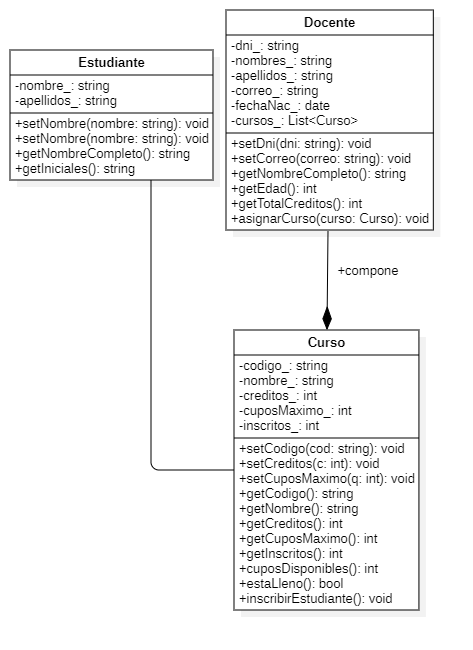

# Semana 3: Herencia y Polimorfismo — Jerarquías, Sobrescritura y Principio de Sustitución

In [11]:
# ── Práctica S3 — Actividad 2: Jerarquía PersonalUniversitario ──────────
from abc import ABC, abstractmethod

class PersonalUniversitario(ABC):
    """Clase base abstracta para todo el personal de la UNAP."""
    TARIFA_HORA_BASE = 75.0  # S/ por hora

    def __init__(self, dni: str, nombres: str, apellidos: str):
        self.__dni = self._validar_dni(dni)
        self._nombres = nombres
        self._apellidos = apellidos

    @staticmethod
    def _validar_dni(dni: str) -> str:
        if not (dni.isdigit() and len(dni) == 8):
            raise ValueError(f"DNI inválido: {dni!r} (debe tener 8 dígitos)")
        return dni

    @property
    def dni(self) -> str:
        return self.__dni

    @property
    def nombre_completo(self) -> str:
        return f"{self._apellidos}, {self._nombres}"

    @abstractmethod
    def calcular_remuneracion(self) -> float:
        """Cada subclase define su propio cálculo."""
        ...

    def __str__(self) -> str:
        return f"{self.nombre_completo} → S/ {self.calcular_remuneracion():.2f}"


class Docente(PersonalUniversitario):
    FACTORES = {"Auxiliar": 1.0, "Asociado": 1.4, "Principal": 1.8}

    def __init__(self, dni: str, nombres: str, apellidos: str,
                 horas: int, categoria: str):
        super().__init__(dni, nombres, apellidos)
        if horas <= 0 or horas > 40:
            raise ValueError("Horas de docencia deben estar en [1,40]")
        if categoria not in self.FACTORES:
            raise ValueError(f"Categoría inválida: {categoria}")
        self._horas = horas
        self._categoria = categoria

    def calcular_remuneracion(self) -> float:
        return self._horas * self.TARIFA_HORA_BASE * self.FACTORES[self._categoria]


class Administrativo(PersonalUniversitario):
    def __init__(self, dni: str, nombres: str, apellidos: str,
                 salario_base: float, bono: float = 0.0):
        super().__init__(dni, nombres, apellidos)
        if salario_base <= 0:
            raise ValueError("El salario base debe ser positivo")
        self._salario_base = salario_base
        self._bono = bono

    def calcular_remuneracion(self) -> float:
        return self._salario_base + self._bono


class Investigador(PersonalUniversitario):
    """Investigador a tiempo completo — remunerado por proyectos activos."""
    REMUNERACION_POR_PROYECTO = 1500.0

    def __init__(self, dni: str, nombres: str, apellidos: str,
                 proyectos: int):
        super().__init__(dni, nombres, apellidos)
        if proyectos < 1:
            raise ValueError("Debe tener al menos 1 proyecto activo")
        self._proyectos = proyectos

    def calcular_remuneracion(self) -> float:
        return self._proyectos * self.REMUNERACION_POR_PROYECTO


def planilla(personal: list[PersonalUniversitario]) -> None:
    """Imprime la planilla usando polimorfismo — sin isinstance()."""
    total = 0.0
    print("=" * 60)
    print("PLANILLA PERSONAL UNIVERSITARIO — UNAP PUNO")
    print("=" * 60)
    for p in personal:
        print(p)  # llama __str__ → calcular_remuneracion polimórfico
        total += p.calcular_remuneracion()
    print("-" * 60)
    print(f"TOTAL PLANILLA: S/ {total:.2f}")


# ── Pruebas ─────────────────────────────────────────────────────────────
personal = [
    Docente("12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"),
    Docente("23456789", "María Elena", "Quispe Torres", 12, "Principal"),
    Administrativo("34567890", "Pedro", "Huanca Lazo", 2800.0, 350.0),
    Investigador("45678901", "Ana Lucía", "Flores Ramos", 2),
]

planilla(personal)

# Verificación LSP — todos son PersonalUniversitario
for p in personal:
    assert isinstance(p, PersonalUniversitario)
    assert p.calcular_remuneracion() > 0
print("\nVerificación LSP: OK — todos los objetos respetan el contrato base")



PLANILLA PERSONAL UNIVERSITARIO — UNAP PUNO
Mamani Quispe, Juan Carlos → S/ 1680.00
Quispe Torres, María Elena → S/ 1620.00
Huanca Lazo, Pedro → S/ 3150.00
Flores Ramos, Ana Lucía → S/ 3000.00
------------------------------------------------------------
TOTAL PLANILLA: S/ 9450.00

Verificación LSP: OK — todos los objetos respetan el contrato base


In [12]:
# ── Verificación LSP para la jerarquía PersonalUniversitario ────────────
def verificar_contrato_personal(p: PersonalUniversitario) -> bool:
    """
    Contrato que TODA subclase debe satisfacer:
    1. nombre_completo retorna string no vacío
    2. calcular_remuneracion() retorna valor > 0
    3. str(p) contiene el nombre completo
    """
    ok = True
    ok = ok and isinstance(p.nombre_completo, str) and len(p.nombre_completo) > 0
    ok = ok and p.calcular_remuneracion() > 0
    ok = ok and p.nombre_completo in str(p)
    return ok


def verificar_lsp(personal: list[PersonalUniversitario]) -> None:
    """Ejecuta el contrato sobre cada objeto y muestra resultados."""
    for p in personal:
        if verificar_contrato_personal(p):
            print(f"OK → {p.nombre_completo}")
        else:
            print(f"FALLA → {p.nombre_completo}")


# ── Pruebas con la jerarquía PersonalUniversitario ──────────────────────
personal = [
    Docente("12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"),
    Docente("23456789", "María Elena", "Quispe Torres", 12, "Principal"),
    Administrativo("34567890", "Pedro", "Huanca Lazo", 2800.0, 350.0),
    Investigador("45678901", "Ana Lucía", "Flores Ramos", 2),
]

verificar_lsp(personal)
print("\nVerificación LSP: OK — todos los objetos respetan el contrato base")


# ── Violación clásica de LSP: Cuadrado hereda de Rectángulo ─────────────
class Figura:
    def area(self) -> float: ...


class Rectangulo(Figura):
    def __init__(self, ancho: float, alto: float):
        self._ancho = ancho
        self._alto = alto

    def set_ancho(self, v: float) -> None: self._ancho = v
    def set_alto(self, v: float) -> None: self._alto = v
    def area(self) -> float: return self._ancho * self._alto


class Cuadrado(Rectangulo):
    def __init__(self, lado: float):
        super().__init__(lado, lado)

    def set_ancho(self, v: float) -> None:
        self._ancho = v
        self._alto = v  # fuerza ambos lados iguales

    def set_alto(self, v: float) -> None:
        self._ancho = v
        self._alto = v  # fuerza ambos lados iguales


def test_rectangulo(r: Rectangulo) -> None:
    """Test que DEBERÍA pasar para cualquier Rectangulo según LSP."""
    r.set_ancho(4)
    r.set_alto(5)
    area_esperada = 20.0
    assert r.area() == area_esperada, f"LSP violado: area={r.area()}, esperado={area_esperada}"


# ── Pruebas con Rectángulo y Cuadrado ──────────────────────────────────
rect = Rectangulo(2, 2)
test_rectangulo(rect)  # ✅ OK

cuad = Cuadrado(2)
try:
    test_rectangulo(cuad)  # ❌ FALLA — viola LSP
except AssertionError as e:
    print(f"LSP VIOLADO en Cuadrado: {e}")
    print("Solución: no heredar Cuadrado de Rectángulo; usar composición o interfaz independiente.")


OK → Mamani Quispe, Juan Carlos
OK → Quispe Torres, María Elena
OK → Huanca Lazo, Pedro
OK → Flores Ramos, Ana Lucía

Verificación LSP: OK — todos los objetos respetan el contrato base
LSP VIOLADO en Cuadrado: LSP violado: area=25, esperado=20.0
Solución: no heredar Cuadrado de Rectángulo; usar composición o interfaz independiente.


In [13]:
class PersonalUniversitario:
    def __init__(self, dni, nombres, apellidos):
        self.dni = dni
        self.nombres = nombres
        self.apellidos = apellidos

    def calcular_remuneracion(self):
        raise NotImplementedError("Debe implementarse en la subclase")

    def identificarse(self):
        return f"{self.apellidos}, {self.nombres} (DNI: {self.dni})"


class Docente(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, horas, categoria):
        super().__init__(dni, nombres, apellidos)
        self.horas = horas
        self.categoria = categoria
        self.tarifa = 75
        self.factor = {"Auxiliar":1.0,"Asociado":1.4,"Principal":1.8}[categoria]

    def calcular_remuneracion(self):
        return self.horas * self.tarifa * self.factor


class Administrativo(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, salario_base, bono=0):
        super().__init__(dni, nombres, apellidos)
        self.salario_base = salario_base
        self.bono = bono

    def calcular_remuneracion(self):
        return self.salario_base + self.bono


def planilla(personal):
    total = 0
    for p in personal:
        print(f"{p.identificarse()} S/ {p.calcular_remuneracion():.2f}")
        total += p.calcular_remuneracion()
    print("TOTAL:", total)


# Demostración polimórfica
personal = [
    Docente("12345678","Juan Carlos","Mamani Quispe",16,"Asociado"),
    Administrativo("34567890","Pedro","Huanca Lazo",2800,350)
]
planilla(personal)


Mamani Quispe, Juan Carlos (DNI: 12345678) S/ 1680.00
Huanca Lazo, Pedro (DNI: 34567890) S/ 3150.00
TOTAL: 4830.0


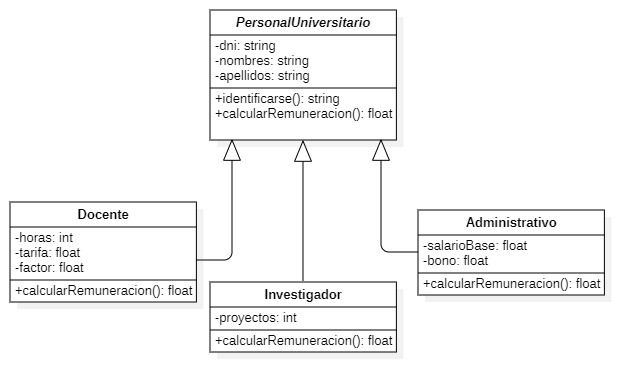